# Classification des émotions faciales — FER2013

## Partie 1 : Préparation et exploration des données

Objectif : télécharger le dataset FER2013, analyser sa structure,
visualiser les images et préparer leur chargement avec PyTorch.

## 1. Importation et décompression du dataset FER2013

Nous utilisons les bibliothèques glob et zipfile pour localiser et décompresser le fichier ZIP du dataset FER2013, afin d'accéder aux images d'entraînement et de test.

In [ ]:
import glob
import zipfile

zip_files = glob.glob("/content/*.zip")
print("Fichiers ZIP trouvés :", zip_files)

with zipfile.ZipFile(zip_files[0], "r") as zip_ref:
    zip_ref.extractall("/content/data")

print("Décompression terminée")

Fichiers ZIP trouvés : ['/content/FER2013.zip']
Décompression terminée


In [ ]:
print(os.listdir("/content/data"))

['test', 'train']


## 2. Exploration du dataset

Nous identifions les sept classes d'émotions présentes dans FER2013, puis nous analysons la répartition des images afin de repérer d'éventuels déséquilibres entre les catégories.

In [ ]:
import os

train_path = "/content/data/train"
test_path = "/content/data/test"

classes = sorted(os.listdir(train_path))

print("Nombre de classes :", len(classes))
print("Liste des émotions :", classes)

Nombre de classes : 7
Liste des émotions : ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


Nous comptons le nombre d'images pour chaque émotion afin d'observer la répartition des classes et de repérer d'éventuels déséquilibres.

In [ ]:
images_par_classe = {}

for emotion in classes:
    dossier = os.path.join(train_path, emotion)
    nombre = len(os.listdir(dossier))

    images_par_classe[emotion] = nombre
    print(f"{emotion} : {nombre} images")

print("\nNombre total d'images :", sum(images_par_classe.values()))

angry : 3995 images
disgust : 436 images
fear : 4097 images
happy : 7215 images
neutral : 4965 images
sad : 4830 images
surprise : 3171 images

Nombre total d'images : 28709


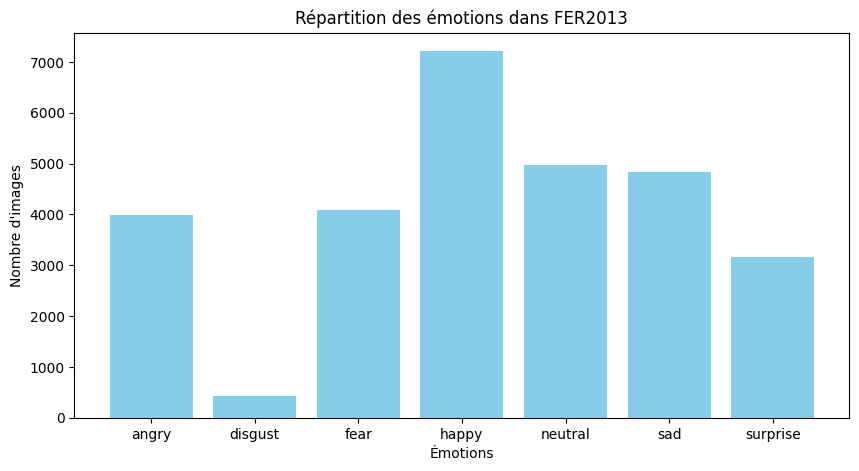

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    images_par_classe.keys(),
    images_par_classe.values(),
    color="skyblue"
)

plt.title("Répartition des émotions dans FER2013")
plt.xlabel("Émotions")
plt.ylabel("Nombre d'images")

plt.show()

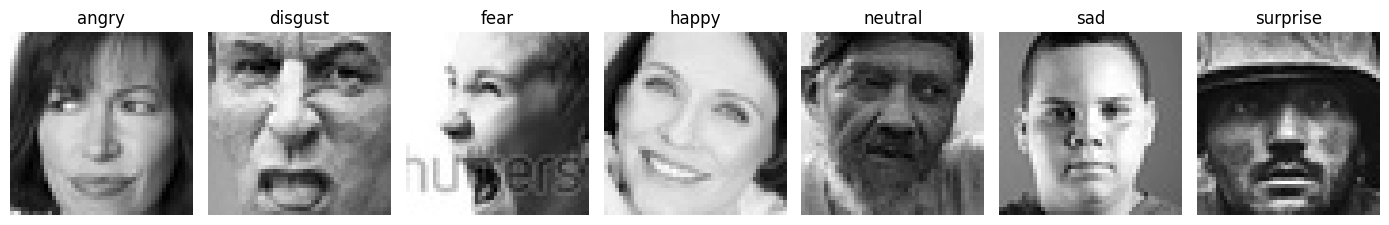

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import os

plt.figure(figsize=(14, 4))

for i, emotion in enumerate(classes):
    dossier = os.path.join(train_path, emotion)
    fichier = os.listdir(dossier)[0]
    chemin = os.path.join(dossier, fichier)

    image = Image.open(chemin).convert("L")

    plt.subplot(1, 7, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(emotion)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
print("Dimensions de l'image :", image.size)

Dimensions de l'image : (48, 48)


In [ ]:
import torch
import numpy as np
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

In [ ]:
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((48, 48)),
    transforms.ToTensor()
])

In [ ]:
train_dataset = datasets.ImageFolder(
    root="/content/data/train",
    transform=transform
)

test_dataset = datasets.ImageFolder(
    root="/content/data/test",
    transform=transform
)

print("Images d'entraînement :", len(train_dataset))
print("Images de test :", len(test_dataset))
print("Classes :", train_dataset.classes)

Images d'entraînement : 28709
Images de test : 7178
Classes : ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

In [ ]:
images, labels = next(iter(train_loader))

print("Dimensions des images :", images.shape)
print("Dimensions des labels :", labels.shape)

Dimensions des images : torch.Size([64, 1, 48, 48])
Dimensions des labels : torch.Size([64])


In [ ]:
from torch.utils.data import random_split

# Fixer une graine pour reproduire les résultats
generator = torch.Generator().manual_seed(42)

# 85 % entraînement, 15 % validation
train_size = int(0.85 * len(train_dataset))
val_size = len(train_dataset) - train_size

train_ds, val_ds = random_split(
    train_dataset,
    [train_size, val_size],
    generator=generator
)

print("Entraînement :", len(train_ds))
print("Validation :", len(val_ds))
print("Test :", len(test_dataset))

Entraînement : 24402
Validation : 4307
Test : 7178


In [ ]:
train_loader = DataLoader(
    train_ds,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Les 3 DataLoader sont prêts ")

Les 3 DataLoader sont prêts 


In [ ]:
for nom, loader in [
    ("Train", train_loader),
    ("Validation", val_loader),
    ("Test", test_loader)
]:
    images, labels = next(iter(loader))

    print(nom)
    print("Images :", images.shape)
    print("Labels :", labels.shape)
    print()

Train
Images : torch.Size([64, 1, 48, 48])
Labels : torch.Size([64])

Validation
Images : torch.Size([64, 1, 48, 48])
Labels : torch.Size([64])

Test
Images : torch.Size([64, 1, 48, 48])
Labels : torch.Size([64])

